## # Google colab link 
- https://colab.research.google.com/drive/1UEfalzS1DAsW0Dwl3lstt-pqxfAYjmE-?usp=sharing

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")

print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, "AB_NYC_2019.csv"))

Using Colab cache for faster access to the 'new-york-city-airbnb-open-data' dataset.
Path to dataset files: /kaggle/input/new-york-city-airbnb-open-data


In [ ]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [ ]:
df.describe(include='all') ## for all feature include with the object

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,48879,4.889500e+04,48874,48895,48895,48895.000000,48895.000000,48895,48895.000000,48895.000000,48895.000000,38843,38843.000000,48895.000000,48895.000000
unique,NaN,47905,NaN,11452,5,221,NaN,NaN,3,NaN,NaN,NaN,1764,NaN,NaN,NaN
top,NaN,Hillside Hotel,NaN,Michael,Manhattan,Williamsburg,NaN,NaN,Entire home/apt,NaN,NaN,NaN,2019-06-23,NaN,NaN,NaN
freq,NaN,18,NaN,417,21661,3920,NaN,NaN,25409,NaN,NaN,NaN,1413,NaN,NaN,NaN
mean,1.901714e+07,NaN,6.762001e+07,NaN,NaN,NaN,40.728949,-73.952170,NaN,152.720687,7.029962,23.274466,NaN,1.373221,7.143982,112.781327
std,1.098311e+07,NaN,7.861097e+07,NaN,NaN,NaN,0.054530,0.046157,NaN,240.154170,20.510550,44.550582,NaN,1.680442,32.952519,131.622289
min,2.539000e+03,NaN,2.438000e+03,NaN,NaN,NaN,40.499790,-74.244420,NaN,0.000000,1.000000,0.000000,NaN,0.010000,1.000000,0.000000
25%,9.471945e+06,NaN,7.822033e+06,NaN,NaN,NaN,40.690100,-73.983070,NaN,69.000000,1.000000,1.000000,NaN,0.190000,1.000000,0.000000
50%,1.967728e+07,NaN,3.079382e+07,NaN,NaN,NaN,40.723070,-73.955680,NaN,106.000000,3.000000,5.000000,NaN,0.720000,1.000000,45.000000
75%,2.915218e+07,NaN,1.074344e+08,NaN,NaN,NaN,40.763115,-73.936275,NaN,175.000000,5.000000,24.000000,NaN,2.020000,2.000000,227.000000


In [ ]:
df.shape

(48895, 16)

In [ ]:
## EDE

In [ ]:
df.isnull().mean() * 100

,0
id,0.000000
name,0.032723
host_id,0.000000
host_name,0.042949
neighbourhood_group,0.000000
neighbourhood,0.000000
latitude,0.000000
longitude,0.000000
room_type,0.000000
price,0.000000


In [ ]:
missing = df.isnull().sum()
missing[missing > 0]

,0
name,16
host_name,21
last_review,10052
reviews_per_month,10052


In [ ]:
df['room_type'].value_counts()

,count
room_type,
Entire home/apt,25409
Private room,22326
Shared room,1160


<Axes: xlabel='room_type', ylabel='count'>

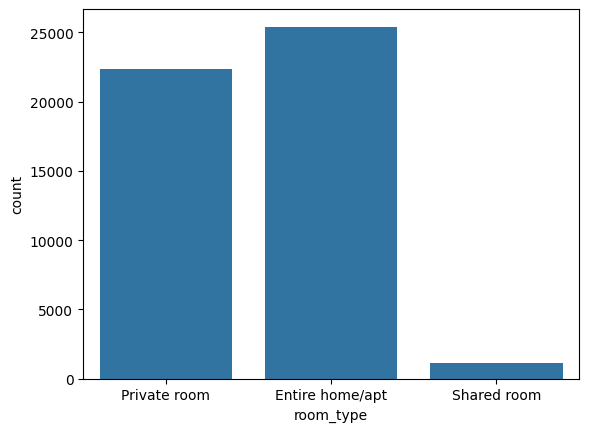

In [ ]:
sns.countplot(x=df['room_type'])

In [ ]:
## numerical feature analysis

array([[<Axes: title={'center': 'price'}>,
        <Axes: title={'center': 'minimum_nights'}>],
       [<Axes: title={'center': 'number_of_reviews'}>,
        <Axes: title={'center': 'reviews_per_month'}>],
       [<Axes: title={'center': 'calculated_host_listings_count'}>,
        <Axes: title={'center': 'availability_365'}>]], dtype=object)

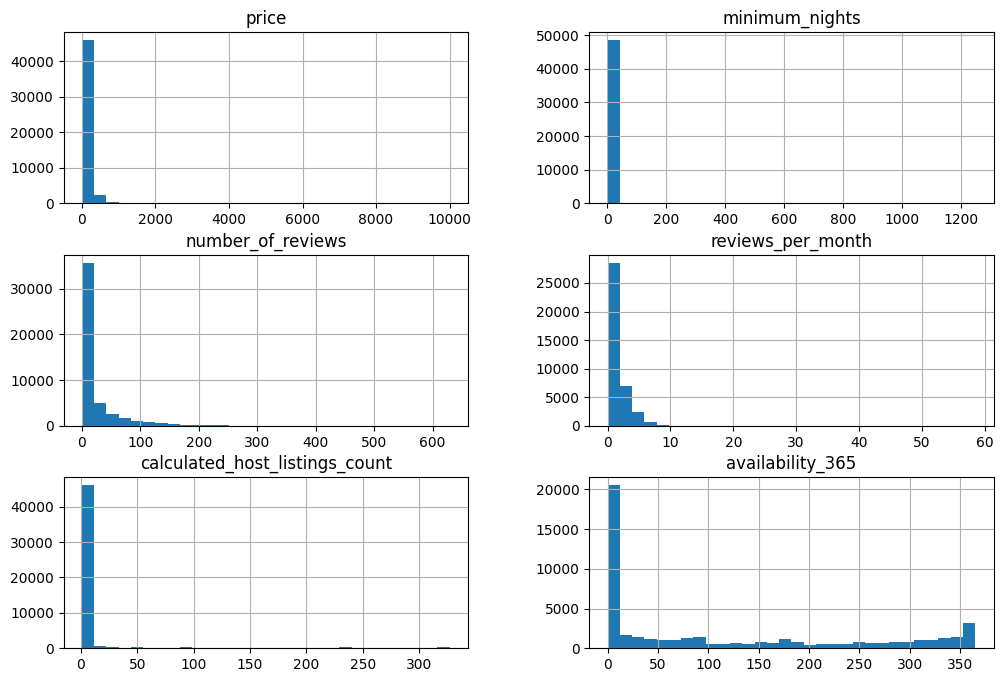

In [ ]:
numerical_cols = ["price", "minimum_nights", "number_of_reviews",
                 "reviews_per_month", "calculated_host_listings_count",
                 "availability_365"]

df[numerical_cols].hist(bins=30, figsize=(12, 8))

<Axes: xlabel='neighbourhood_group', ylabel='count'>

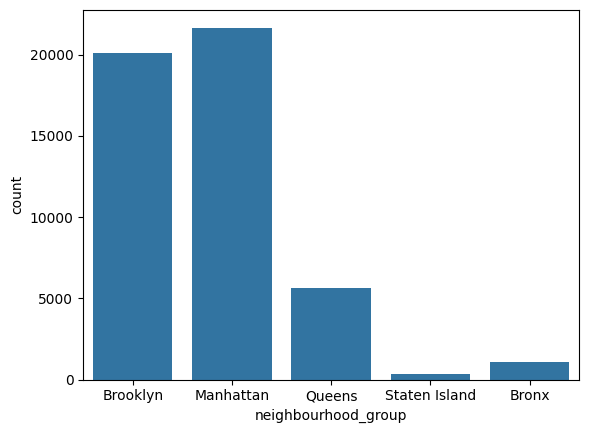

In [ ]:
sns.countplot(x=df['neighbourhood_group'])

<Axes: xlabel='room_type', ylabel='price'>

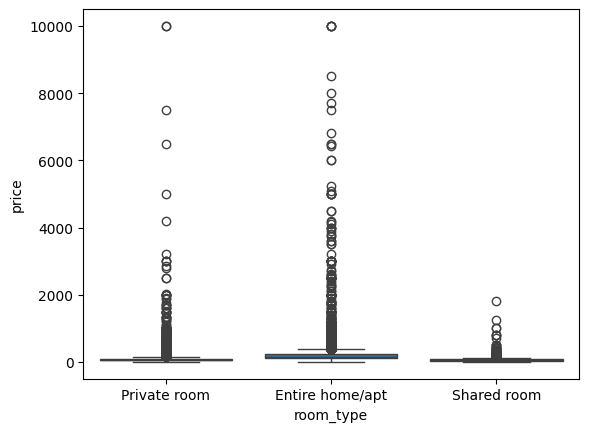

In [ ]:
sns.boxplot(df,x='room_type',y='price')

In [ ]:
df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

<Axes: >

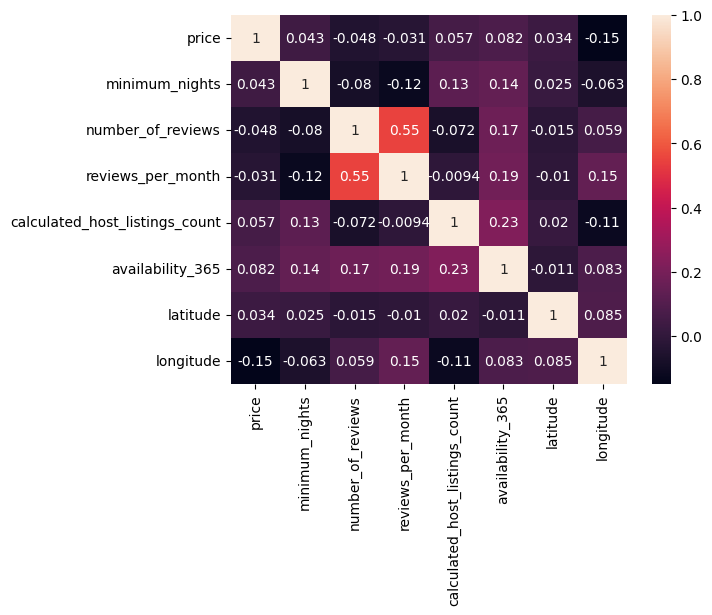

In [ ]:
corr = df[numerical_cols+['latitude','longitude']].corr()
sns.heatmap(corr,annot=True)

<Axes: xlabel='longitude', ylabel='latitude'>

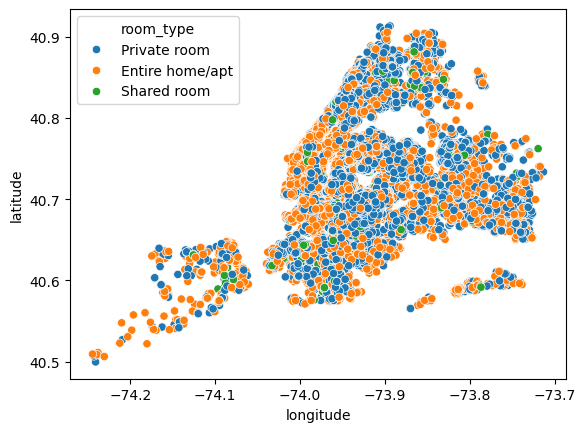

In [ ]:
sns.scatterplot(df,x='longitude',y='latitude',hue='room_type')

In [ ]:
## data cleaing

In [ ]:
## drop feature that is not use in the model and not require
df_clean = df.drop(columns=['id','name','host_id','host_name','last_review'])

In [ ]:
df_clean.head()

,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
0,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,0.21,6,365
1,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,0.38,2,355
2,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,1,365
3,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,4.64,1,194
4,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,0.10,1,0


In [ ]:
df_clean.isnull().mean() * 100

,0
neighbourhood_group,0.000000
neighbourhood,0.000000
latitude,0.000000
longitude,0.000000
room_type,0.000000
price,0.000000
minimum_nights,0.000000
number_of_reviews,0.000000
reviews_per_month,20.558339
calculated_host_listings_count,0.000000


In [ ]:
df_clean.columns

Index(['neighbourhood_group', 'neighbourhood', 'latitude', 'longitude',
       'room_type', 'price', 'minimum_nights', 'number_of_reviews',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

In [ ]:
## reviews per month Nan it is per month reviews and nan is indicate this perticular month no review for any house

df_clean['reviews_per_month'] = df_clean['reviews_per_month'].fillna(0)

In [ ]:
## remove outliers base on caping not used triming
df_clean.select_dtypes('number').skew()

,0
latitude,0.237167
longitude,1.284210
price,19.118939
minimum_nights,21.827275
number_of_reviews,3.690635
reviews_per_month,3.300723
calculated_host_listings_count,7.933174
availability_365,0.763408


In [ ]:
price_cap = df_clean['price'].quantile(0.99)
night_cap = df_clean['minimum_nights'].quantile(0.99)

In [ ]:
df_clean['price'] = df_clean['price'].clip(upper=price_cap)
df_clean['minimum_nights'] = df_clean['minimum_nights'].clip(upper=night_cap)

<Axes: xlabel='room_type', ylabel='price'>

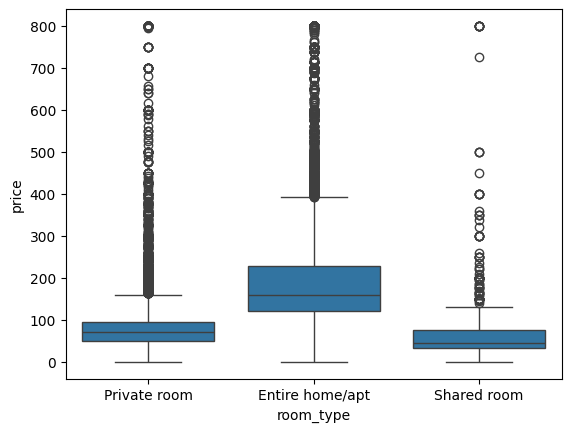

In [ ]:
sns.boxplot(df_clean,x='room_type',y='price')

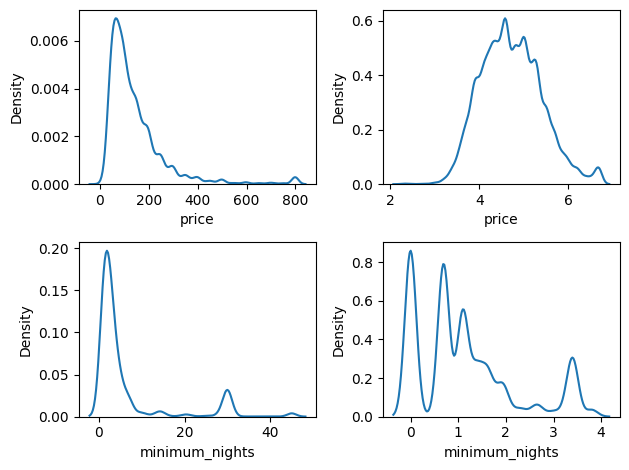

In [ ]:
plt.subplot(2,2,1)
sns.kdeplot(df_clean['price'])
plt.subplot(2,2,2)
sns.kdeplot(np.log(df_clean['price']))
plt.subplot(2,2,3)
sns.kdeplot(df_clean['minimum_nights'])
plt.subplot(2,2,4)
sns.kdeplot(np.log(df_clean['minimum_nights']))

plt.tight_layout()
plt.show()

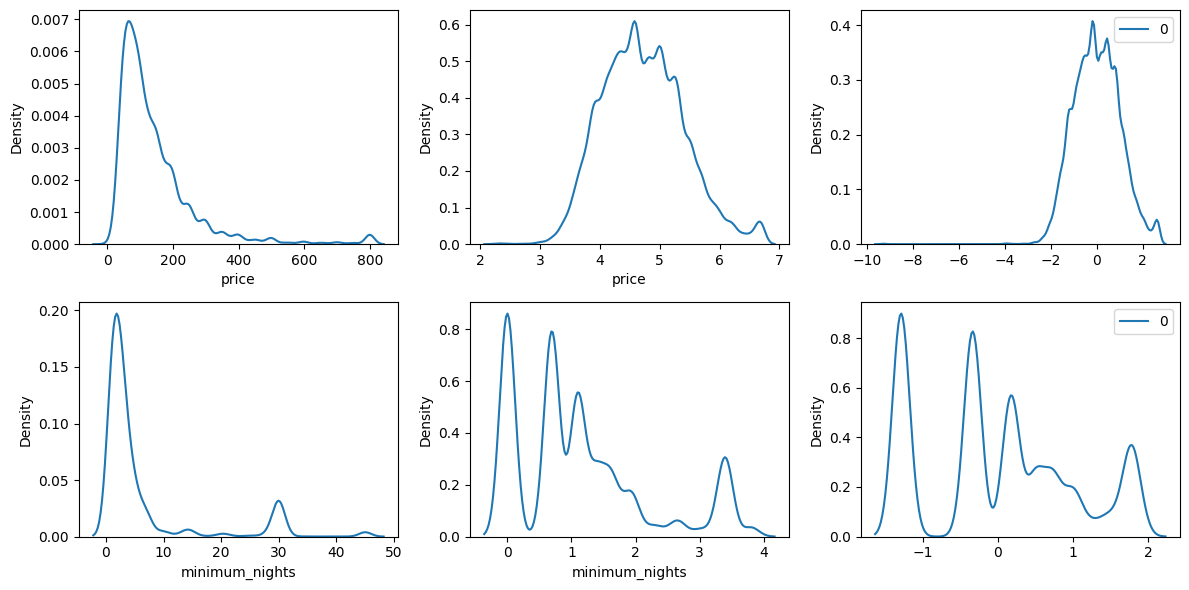

In [ ]:
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer()
price = pt.fit_transform(df_clean[['price']])
minimum_nights = pt.fit_transform(df_clean[['minimum_nights']])

plt.figure(figsize=(12,6))

plt.subplot(2,3,1)
sns.kdeplot(df_clean['price'])
plt.subplot(2,3,2)
sns.kdeplot(np.log(df_clean['price']))

plt.subplot(2,3,3)
sns.kdeplot(price)

plt.subplot(2,3,4)
sns.kdeplot(df_clean['minimum_nights'])
plt.subplot(2,3,5)
sns.kdeplot(np.log(df_clean['minimum_nights']))

plt.subplot(2,3,6)
sns.kdeplot(minimum_nights)

plt.tight_layout()
plt.show()

In [ ]:
## train test split

X = df_clean.drop(columns=['room_type'])
y = df_clean['room_type']

In [ ]:
## import the train test split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
# stratify it is use to equal part to split all class both side train and test side

# For example, if a dataset contains 90% negative cases and 10% positive cases, setting stratify=y ensures that both the training and test splits maintain that exact 90:10 ratio rather than leaving it up to random chance.

## it is solve the imbalance dataset problem

In [ ]:
## create preprocessing pipeline

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, PowerTransformer
from sklearn.impute import SimpleImputer

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   neighbourhood_group             48895 non-null  object 
 1   neighbourhood                   48895 non-null  object 
 2   latitude                        48895 non-null  float64
 3   longitude                       48895 non-null  float64
 4   room_type                       48895 non-null  object 
 5   price                           48895 non-null  int64  
 6   minimum_nights                  48895 non-null  int64  
 7   number_of_reviews               48895 non-null  int64  
 8   reviews_per_month               48895 non-null  float64
 9   calculated_host_listings_count  48895 non-null  int64  
 10  availability_365                48895 non-null  int64  
dtypes: float64(3), int64(5), object(3)
memory usage: 4.1+ MB


In [ ]:
num_cols = ["price", "minimum_nights", "number_of_reviews",
                 "calculated_host_listings_count",
                 "availability_365",]
geo_cols = [ "latitude", "longitude"]
zero_cols = ['reviews_per_month']
cat_cols = ['neighbourhood_group', 'neighbourhood']

In [ ]:
zero_cols_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='constant',fill_value=0)),
    ('log',FunctionTransformer(np.log1p)),
    ('scale',StandardScaler())
])

geo_cols_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scale',StandardScaler())
])


## use auto standerscaler by defualt use in the powerTrasformer not need to apply

## not use powertrasformer this place but try to new something and data are the right skewed and apply only Function trasformer
numerical_cols_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('power',PowerTransformer(standardize=True))
])

categorical_cols_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='most_frequent')),
    ('onehot',OneHotEncoder(handle_unknown='ignore',drop='first'))
])

In [ ]:
preprocessor = ColumnTransformer([
    ('numerical_pipeline',numerical_cols_pipeline,num_cols),
    ('zero_pipeline',zero_cols_pipeline,zero_cols),
    ('geo_pipeline',geo_cols_pipeline,geo_cols),
    ('categorical_pipeline',categorical_cols_pipeline,cat_cols)
])

In [ ]:
## SMOTE -> synthetic minority oversampling
## SMOTE is use to imbalance dataset fill
## and it is random value fill
### and high change to add outliers and data leakage

In [ ]:
## and use to the class_weight perameter it is use to high weight apply on the minority class

## problem is the tree base some algo not provide the class_weight

In [ ]:
## best way solve imbalance dataset

# Stratified split.
# Baseline with class_weight='balanced'.
# Evaluate with F1, recall, and PR-AUC, not accuracy.
# Tune the decision threshold.
# Try SMOTE inside an imblearn pipeline only if the above isn't enough.

In [ ]:
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
models = {
    "Logistic Regression" : LogisticRegression(class_weight="balanced",random_state=42),
    "Decision Tree"       : DecisionTreeClassifier(class_weight="balanced",random_state=42),
    "Random Forest"       : RandomForestClassifier(class_weight="balanced", random_state=42),
    "Gradient Boosting"   : GradientBoostingClassifier(random_state=42),
}

for name, model in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("classifier", model)])

    # Accuracy alone can be misleading on imbalanced classes, so we use macro f1
    # both: plain accuracy and macro f1 (which treats every class equally)

    accuracy = cross_val_score(pipe, X_train, y_train,cv=3,scoring="accuracy")
    macrof1 = cross_val_score(pipe, X_train, y_train,cv=3,scoring="f1_macro")

    print(f"{name} -> Accuracy: {accuracy.mean():.3f} , F1: {macrof1.mean():.3f}")

Logistic Regression -> Accuracy: 0.731 , F1: 0.580
Decision Tree -> Accuracy: 0.785 , F1: 0.651
Random Forest -> Accuracy: 0.853 , F1: 0.717
Gradient Boosting -> Accuracy: 0.850 , F1: 0.707


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

best_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier",   RandomForestClassifier(class_weight='balanced'))
])

param_distribution = {
    "classifier__n_estimators" : [100,200,150,300],
    "classifier__max_depth": [8, 12, 15, 20, None],
    "classifier__min_samples_split": [2, 5, 10],
}

search = RandomizedSearchCV(
    estimator=best_pipeline,
    param_distributions=param_distribution,
    n_iter=10,
    cv=3,
    scoring="f1_macro",
    random_state=42
)

search.fit(X_train, y_train)

RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('numerical_pipeline',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('power',
                                                                                                PowerTransformer())]),
                                                                               ['price',
                                                                                'minimum_nights',
                                                                                'number_of_reviews',
                                                                                'calculated_host_listings_count',
                                                                                'availability_365']),
                                                                              ('zero_pipeline',
                                                                               Pipeline(steps=[('imp...
                                                                                               ('onehot',
                                                                                                OneHotEncoder(drop='first',
                                                                                                              handle_unknown='ignore'))]),
                                                                               ['neighbourhood_group',
                                                                                'neighbourhood'])])),
                                             ('classifier',
                                              RandomForestClassifier(class_weight='balanced'))]),
                   param_distributions={'classifier__max_depth': [8, 12, 15, 20,
                                                                  None],
                                        'classifier__min_samples_split': [2, 5,
                                                                          10],
                                        'classifier__n_estimators': [100, 200,
                                                                     150,
                                                                     300]},
                   random_state=42, scoring='f1_macro')

In [ ]:
print("Best Parameters: ", search.best_params_)
print("Best CV Macro-F1: ", search.best_score_)

Best Parameters:  {'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__max_depth': None}
Best CV Macro-F1:  0.7359341205081571


In [ ]:

from sklearn.metrics import accuracy_score, confusion_matrix,f1_score
best_pipeline = search.best_estimator_

y_pred = best_pipeline.predict(X_test)

print(f"Accuracy Score: {accuracy_score(y_test, y_pred)}")
print(f"F1 Score: {f1_score(y_test, y_pred, average="macro")}")

Accuracy Score: 0.858574496369772
F1 Score: 0.7595871259824943


In [ ]:
confusion_matrix(y_test,y_pred)

array([[4467,  615,    0],
       [ 614, 3834,   17],
       [  22,  115,   95]])

<Axes: >

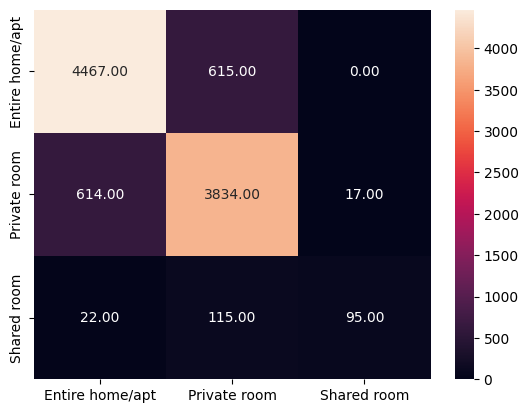

In [ ]:
sns.heatmap(confusion_matrix(y_test,y_pred), annot=True, fmt=".2f",
            xticklabels=best_pipeline.classes_, yticklabels=best_pipeline.classes_)

In [ ]:
import joblib

joblib.dump(best_pipeline, "Model_Pipeline.pkl",compress=3)

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

sw = compute_sample_weight('balanced', y_train_enc)

In [ ]:
X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, f1_score

model = XGBClassifier(
    random_state=42,
    n_estimators=300,
    learning_rate=0.1,
    max_depth=6,
    eval_metric='mlogloss',
    n_jobs=-1
)

model.fit(X_train_p, y_train_enc, sample_weight=sw)

y_pred = model.predict(X_test_p)
print(classification_report(y_test_enc, y_pred, target_names=le.classes_, digits=3))
print("Macro F1:", f1_score(y_test_enc, y_pred, average='macro'))

                 precision    recall  f1-score   support

Entire home/apt      0.881     0.890     0.885      5082
   Private room      0.859     0.816     0.837      4465
    Shared room      0.340     0.595     0.433       232

       accuracy                          0.849      9779
      macro avg      0.693     0.767     0.718      9779
   weighted avg      0.858     0.849     0.853      9779

Macro F1: 0.7183157727332441


In [ ]:
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
from xgboost import XGBClassifier

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

X_train_p = preprocessor.fit_transform(X_train)
X_test_p = preprocessor.transform(X_test)

base_w = compute_sample_weight('balanced', y_train_enc)

param_grid = [
    dict(max_depth=d, learning_rate=lr, n_estimators=n, subsample=ss,
         colsample_bytree=cs, min_child_weight=mcw, power=p)
    for d in [4, 6, 8] for lr in [0.05, 0.1] for n in [300, 500]
    for ss in [0.8, 1.0] for cs in [0.8, 1.0] for mcw in [1, 3]
    for p in [0.3, 0.5, 0.7, 1.0]          # weight strength: 1.0 = full balanced
]
rng = np.random.RandomState(42)
trials = [param_grid[i] for i in rng.choice(len(param_grid), 25, replace=False)]

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
results = []
for params in trials:
    p = params.pop('power')
    scores = []
    for tr, va in skf.split(X_train_p, y_train_enc):
        m = XGBClassifier(random_state=42, eval_metric='mlogloss', n_jobs=-1, **params)
        m.fit(X_train_p[tr], y_train_enc[tr], sample_weight=base_w[tr] ** p)
        scores.append(f1_score(y_train_enc[va], m.predict(X_train_p[va]), average='macro'))
    results.append((np.mean(scores), p, params))

results.sort(key=lambda r: r[0], reverse=True)
best_score, best_p, best_params = results[0]
print(best_score, best_p, best_params)

0.7502551685412602 0.5 {'max_depth': 8, 'learning_rate': 0.05, 'n_estimators': 300, 'subsample': 0.8, 'colsample_bytree': 0.8, 'min_child_weight': 3}
